<a href="https://colab.research.google.com/github/Tavonga03/ML/blob/ML/TUGAS_KELOMPOK.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
df= pd.read_csv("/content/adult.data")


bagian 1


*   identifikasi pola missing data


Ukruan  dataset  (32561, 15)
       age         workclass  fnlwgt   education  education-num  \
0       39         State-gov   77516   Bachelors             13   
1       50  Self-emp-not-inc   83311   Bachelors             13   
2       38           Private  215646     HS-grad              9   
3       53           Private  234721        11th              7   
4       28           Private  338409   Bachelors             13   
...    ...               ...     ...         ...            ...   
32556   27           Private  257302  Assoc-acdm             12   
32557   40           Private  154374     HS-grad              9   
32558   58           Private  151910     HS-grad              9   
32559   22           Private  201490     HS-grad              9   
32560   52      Self-emp-inc  287927     HS-grad              9   

           marital-status         occupation   relationship   race     sex  \
0           Never-married       Adm-clerical  Not-in-family  White    Male   
1      Mar

/tmp/ipykernel_2727/272748671.py:207: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


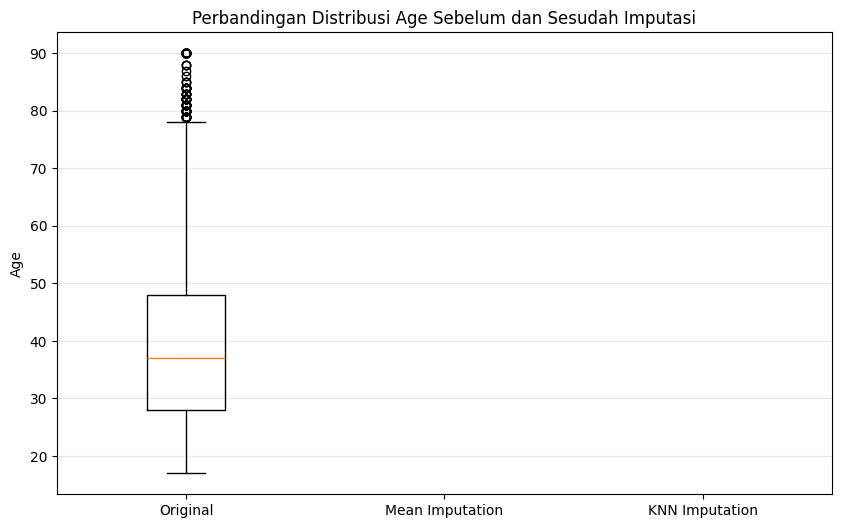


A5 — HASIL PERBANDINGAN MODEL
            Method        MAE       RMSE
0  Mean Imputation  10.959084  13.446566
1   KNN Imputation  10.959084  13.446566


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

df= pd.read_csv("/content/adult.data", header=None,  names=columns,skipinitialspace=True)
columns = [
    "age",
    "workclass",
    "fnlwgt",
    "education",
    "education-num",
    "marital-status",
    "occupation",
    "relationship",
    "race",
    "sex",
    "capital-gain",
    "capital-loss",
    "hours-per-week",
    "native-country",
    "income"
]
# menampilkan ukuran dataset
print("Ukruan  dataset ", df.shape)

#mengubah tanda ? nenjadi nan

df= df.replace("?", np.nan)
print(df)

#menghitung jumlah missing value

missingcount= df.isnull().sum()

#menghitung persentase missing value

missingpercent= (df.isnull().mean() *100).round(2)

# membuat tabel missing value
missingtable = pd.DataFrame({
    "Missing Count": missingcount,
    "Missing Percentage (%)": missingpercent
})

#menampilkan kolom yang memiliki missing value

missingtable= missingtable[missingtable["Missing Count"]>0]
print("\n Missing Value Analysis:")
print(missingtable)

print("=========================================================")

# ============================================================
# A2 — KLASIFIKASI PROPORSI MISSING VALUE
# ============================================================

def classify_missing(percent):
    if percent < 5:
        return "Kecil (<5%)"
    elif percent <= 30:
        return "Sedang (5–30%)"
    else:
        return "Besar (>30%)"

missingtable["Category"] = missingtable[
    "Missing Percentage (%)"
].apply(classify_missing)

print("Klasifikasi Missing Value:")
print(missingtable)


# ============================================================
# A3.1 — DELETION
# ============================================================

df_delete = df.dropna()

print("Dataset sebelum deletion :", df.shape)
print("Dataset setelah deletion :", df_delete.shape)

print("Jumlah baris yang dihapus :",
      df.shape[0] - df_delete.shape[0])

# ============================================================
# A5 — PERBANDINGAN MODEL: MEAN IMPUTATION VS KNN IMPUTATION (Moved up to define variables)
# ============================================================

# ------------------------------------------------------------
# 1. Pilih data numerik
# ------------------------------------------------------------

numeric_columns = [
    "age",
    "fnlwgt",
    "education-num",
    "capital-gain",
    "capital-loss",
    "hours-per-week"
]

data = df[numeric_columns].copy()

# ------------------------------------------------------------
# 2. Buat missing value pada AGE
# ------------------------------------------------------------

np.random.seed(42)

# Simpan nilai age asli
original_age = data["age"].copy()

# Pilih 10% data secara acak
missing_indices = np.random.choice(
    data.index,
    size=int(0.10 * len(data)),
    replace=False
)

# Buat age menjadi missing
data.loc[missing_indices, "age"] = np.nan

print("Jumlah missing value pada age:")
print(data["age"].isnull().sum())

# ------------------------------------------------------------
# 3. Pisahkan data untuk evaluasi
# ------------------------------------------------------------

# Data yang age-nya TIDAK missing digunakan sebagai training
train_data = data.drop(index=missing_indices)

# Data yang age-nya dibuat missing digunakan sebagai testing
test_data = data.loc[missing_indices]

# Nilai age asli sebagai target sebenarnya
y_test = original_age.loc[missing_indices]

# ------------------------------------------------------------
# 4. MEAN IMPUTATION
# ------------------------------------------------------------

mean_imputer = SimpleImputer(strategy="mean")

train_mean = mean_imputer.fit_transform(train_data)
test_mean = mean_imputer.transform(test_data)

# Ubah kembali menjadi DataFrame
train_mean = pd.DataFrame(
    train_mean,
    columns=numeric_columns,
    index=train_data.index
)

test_mean = pd.DataFrame(
    test_mean,
    columns=numeric_columns,
    index=test_data.index
)

# ------------------------------------------------------------
# 5. KNN IMPUTATION
# ------------------------------------------------------------

knn_imputer = KNNImputer(n_neighbors=5)

train_knn = knn_imputer.fit_transform(train_data)
test_knn = knn_imputer.transform(test_data)

train_knn = pd.DataFrame(
    train_knn,
    columns=numeric_columns,
    index=train_data.index
)

test_knn = pd.DataFrame(
    test_knn,
    columns=numeric_columns,
    index=test_data.index
)

# Define age_mean and age_knn for A4 after imputation
age_mean = test_mean["age"]
age_knn = test_knn["age"]

# ============================================================
# A4 — PERBANDINGAN DISTRIBUSI SEBELUM DAN SESUDAH IMPUTASI
# ============================================================

# Membuat dataframe untuk perbandingan
age_comparison = pd.DataFrame({
    "Original": original_age,
    "Mean Imputation": age_mean,
    "KNN Imputation": age_knn
})

# ============================================================
# BOXPLOT
# ============================================================

plt.figure(figsize=(10, 6))

plt.boxplot(
    [
        age_comparison["Original"],
        age_comparison["Mean Imputation"],
        age_comparison["KNN Imputation"]
    ],
    labels=[
        "Original",
        "Mean Imputation",
        "KNN Imputation"
    ]
)

plt.title("Perbandingan Distribusi Age Sebelum dan Sesudah Imputasi")
plt.ylabel("Age")
plt.grid(axis="y", alpha=0.3)

plt.show()


# Remaining parts of A5
# ------------------------------------------------------------
# 6. Linear Regression — Mean Imputation
# ------------------------------------------------------------

features = [
    "fnlwgt",
    "education-num",
    "capital-gain",
    "capital-loss",
    "hours-per-week"
]

X_train_mean = train_mean[features]
y_train_mean = train_mean["age"]

X_test_mean = test_mean[features]

model_mean = LinearRegression()

model_mean.fit(
    X_train_mean,
    y_train_mean
)

prediction_mean = model_mean.predict(
    X_test_mean
)

# ------------------------------------------------------------
# 7. Linear Regression — KNN Imputation
# ------------------------------------------------------------

X_train_knn = train_knn[features]
y_train_knn = train_knn["age"]

X_test_knn = test_knn[features]

model_knn = LinearRegression()

model_knn.fit(
    X_train_knn,
    y_train_knn
)

prediction_knn = model_knn.predict(
    X_test_knn
)

# ------------------------------------------------------------
# 8. Evaluasi Model
# ------------------------------------------------------------

mae_mean = mean_absolute_error(
    y_test,
    prediction_mean
)

rmse_mean = np.sqrt(
    mean_squared_error(
        y_test,
        prediction_mean
    )
)

mae_knn = mean_absolute_error(
    y_test,
    prediction_knn
)

rmse_knn = np.sqrt(
    mean_squared_error(
        y_test,
        prediction_knn
    )
)

# ------------------------------------------------------------
# 9. Tampilkan hasil
# ------------------------------------------------------------

results = pd.DataFrame({
    "Method": [
        "Mean Imputation",
        "KNN Imputation"
    ],
    "MAE": [
        mae_mean,
        mae_knn
    ],
    "RMSE": [
        rmse_mean,
        rmse_knn
    ]
})

print("\n========================================")
print("A5 — HASIL PERBANDINGAN MODEL")
print("========================================")

print(results)

# BAGIAN B — TRANSFORMASI DATA KATEGORIKAL & TIPE DATA

## B1. Identifikasi Kolom Kategorikal

Pada tahap ini, saya mengidentifikasi seluruh kolom kategorikal pada dataset Adult setelah dilakukan proses pada Bagian A. Kolom kategorikal yang terdapat pada dataset adalah `workclass`, `education`, `marital-status`, `occupation`, `relationship`, `race`, `sex`, `native-country`, dan `income`.

Saya mengelompokkan kolom tersebut menjadi data nominal dan ordinal. Kolom `education` termasuk ordinal karena memiliki urutan tingkat pendidikan yang bermakna. Sementara itu, `workclass`, `marital-status`, `occupation`, `relationship`, `race`, `sex`, dan `native-country` termasuk nominal karena kategorinya tidak memiliki urutan tertentu. Kolom `income` merupakan variabel kategorikal yang digunakan sebagai target.

Saya menampilkan jumlah kategori unik dan distribusi setiap kategori menggunakan `nunique()` dan `value_counts()`.

```python
categorical_columns = [
    "workclass",
    "education",
    "marital-status",
    "occupation",
    "relationship",
    "race",
    "sex",
    "native-country",
    "income"
]

for col in categorical_columns:
    print("\n" + "=" * 60)
    print(f"Kolom: {col}")
    print(f"Jumlah kategori unik: {df[col].nunique(dropna=True)}")
    print("Distribusi kategori:")
    print(df[col].value_counts(dropna=False))
```

Hasil dari tahap ini digunakan untuk menentukan metode encoding yang sesuai pada tahap berikutnya.



## B2. Pemilihan Teknik Encoding

Berdasarkan karakteristik setiap variabel, saya memilih teknik encoding yang berbeda.

Kolom `education` diperlakukan sebagai data ordinal karena memiliki urutan tingkat pendidikan. Oleh karena itu, saya menggunakan encoding berdasarkan urutan pendidikan.

Untuk kolom nominal seperti `workclass`, `marital-status`, `occupation`, `relationship`, `race`, `sex`, dan `native-country`, saya menggunakan One-Hot Encoding. Metode ini dipilih karena kategori pada variabel tersebut tidak memiliki hubungan urutan.

Untuk kolom nominal dengan jumlah kategori relatif banyak seperti `native-country`, alternatif yang dapat digunakan adalah frequency encoding atau target encoding. Frequency encoding mengganti setiap kategori dengan frekuensi kemunculannya. Target encoding menggunakan informasi dari variabel target. Target encoding harus dilakukan dengan hati-hati karena dapat menyebabkan data leakage apabila informasi target dari data uji ikut digunakan saat membuat encoding.



## B3. Penerapan Encoding

Pada tahap ini, saya menerapkan encoding pada variabel kategorikal. Kolom `education` diubah menjadi nilai numerik berdasarkan urutan tingkat pendidikan, sedangkan variabel nominal diubah menggunakan One-Hot Encoding.

```python
import pandas as pd
from sklearn.preprocessing import OneHotEncoder

df_encoded = df.copy()

print("Shape sebelum encoding:", df_encoded.shape)

# Ordinal encoding untuk education
education_order = [
    "Preschool",
    "1st-4th",
    "5th-6th",
    "7th-8th",
    "9th",
    "10th",
    "11th",
    "12th",
    "HS-grad",
    "Some-college",
    "Assoc-voc",
    "Assoc-acdm",
    "Bachelors",
    "Masters",
    "Prof-school",
    "Doctorate"
]

education_mapping = {
    category: number
    for number, category in enumerate(education_order)
}

df_encoded["education"] = df_encoded["education"].map(
    education_mapping
)

# One-Hot Encoding untuk data nominal
nominal_columns = [
    "workclass",
    "marital-status",
    "occupation",
    "relationship",
    "race",
    "sex",
    "native-country"
]

encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

encoded_array = encoder.fit_transform(
    df_encoded[nominal_columns].fillna("Missing")
)

encoded_columns = encoder.get_feature_names_out(
    nominal_columns
)

encoded_df = pd.DataFrame(
    encoded_array,
    columns=encoded_columns,
    index=df_encoded.index
)

df_encoded = df_encoded.drop(
    columns=nominal_columns
)

df_encoded = pd.concat(
    [df_encoded, encoded_df],
    axis=1
)

# Encoding target income
income_mapping = {
    "<=50K": 0,
    ">50K": 1
}

df_encoded["income"] = df_encoded["income"].map(
    income_mapping
)

print("Shape setelah encoding:", df_encoded.shape)
```

Jumlah kolom berubah setelah proses encoding karena satu kolom kategorikal dapat berubah menjadi beberapa kolom biner. Sebagai contoh, satu variabel dengan beberapa kategori akan menghasilkan beberapa kolom baru melalui One-Hot Encoding.



## B4. Pemeriksaan Tipe Data

Setelah encoding, saya memeriksa kembali tipe data seluruh kolom untuk memastikan bahwa data yang seharusnya numerik tidak masih terbaca sebagai `object`.

```python
print("Data types setelah encoding:")
print(df_encoded.dtypes)

print("\nKolom yang masih bertipe object:")

object_columns = df_encoded.select_dtypes(
    include=["object"]
).columns

print(object_columns.tolist())
```

Saya kemudian memastikan kolom numerik memiliki tipe data numerik.

```python
numeric_columns = [
    "age",
    "fnlwgt",
    "education",
    "education-num",
    "capital-gain",
    "capital-loss",
    "hours-per-week"
]

for col in numeric_columns:
    df_encoded[col] = pd.to_numeric(
        df_encoded[col],
        errors="coerce"
    )

print("\nData types setelah diperbaiki:")
print(df_encoded.dtypes)
```

Pemeriksaan ini dilakukan agar data dapat digunakan dengan benar pada tahap preprocessing dan pemodelan machine learning.



## B5. Train-Test Split dan Data Leakage

Jika dataset akan digunakan untuk pemodelan machine learning, saya harus melakukan pembagian data menjadi data latih dan data uji sebelum melakukan fitting encoding.

Urutan yang benar adalah:

1. Membagi dataset menjadi data training dan testing.
2. Melakukan `fit` encoder hanya menggunakan data training.
3. Melakukan transformasi terhadap data training.
4. Menggunakan encoder yang sama untuk melakukan transformasi terhadap data testing.

Contohnya:

```python
from sklearn.model_selection import train_test_split

X = df.drop(columns=["income"])
y = df["income"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
```

Kemudian encoder hanya di-fit pada data training:

```python
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

X_train_encoded = encoder.fit_transform(
    X_train[nominal_columns].fillna("Missing")
)

X_test_encoded = encoder.transform(
    X_test[nominal_columns].fillna("Missing")
)
```

Perbedaannya adalah:

```text
X_train → fit_transform()
X_test  → transform()
```

Encoding tidak sebaiknya di-fit pada seluruh dataset sebelum train-test split karena dapat menyebabkan data leakage. Jika informasi dari data uji digunakan ketika membuat encoding, maka proses preprocessing telah menggunakan informasi yang seharusnya hanya tersedia pada data training. Hal tersebut dapat membuat evaluasi model menjadi terlalu optimis dan tidak menggambarkan performa model pada data baru.

Dengan demikian, urutan preprocessing yang digunakan adalah **train-test split terlebih dahulu, kemudian fitting encoding hanya pada data training, dan akhirnya menerapkan encoder yang sama pada data training dan testing**.


In [ ]:
# ============================================================
# B3 — PENERAPAN ENCODING
# ============================================================

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder

# Pisahkan fitur dan target
X = df.drop(columns=["income"])
y = df["income"]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Shape X sebelum encoding :", X.shape)
print("Shape X_train            :", X_train.shape)
print("Shape X_test             :", X_test.shape)

# ------------------------------------------------------------
# Ordinal Encoding — education
# ------------------------------------------------------------

education_order = [
    "Preschool",
    "1st-4th",
    "5th-6th",
    "7th-8th",
    "9th",
    "10th",
    "11th",
    "12th",
    "HS-grad",
    "Some-college",
    "Assoc-voc",
    "Assoc-acdm",
    "Bachelors",
    "Masters",
    "Prof-school",
    "Doctorate"
]

education_mapping = {
    category: number
    for number, category in enumerate(education_order)
}

X_train["education"] = X_train["education"].map(education_mapping)
X_test["education"] = X_test["education"].map(education_mapping)

# ------------------------------------------------------------
# One-Hot Encoding — nominal variables
# ------------------------------------------------------------

nominal_columns = [
    "workclass",
    "marital-status",
    "occupation",
    "relationship",
    "race",
    "sex",
    "native-country"
]

encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

# FIT hanya pada training data
X_train_encoded_array = encoder.fit_transform(
    X_train[nominal_columns].fillna("Missing")
)

# TEST hanya ditransform menggunakan encoder yang sama
X_test_encoded_array = encoder.transform(
    X_test[nominal_columns].fillna("Missing")
)

encoded_columns = encoder.get_feature_names_out(
    nominal_columns
)

# Jadikan DataFrame
X_train_encoded = pd.DataFrame(
    X_train_encoded_array,
    columns=encoded_columns,
    index=X_train.index
)

X_test_encoded = pd.DataFrame(
    X_test_encoded_array,
    columns=encoded_columns,
    index=X_test.index
)

# Hapus kolom nominal asli
X_train = X_train.drop(columns=nominal_columns)
X_test = X_test.drop(columns=nominal_columns)

# Gabungkan kembali
X_train = pd.concat(
    [X_train, X_train_encoded],
    axis=1
)

X_test = pd.concat(
    [X_test, X_test_encoded],
    axis=1
)

print("\nShape setelah encoding:")
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

# Encode target income
income_mapping = {
    "<=50K": 0,
    ">50K": 1
}

y_train = y_train.map(income_mapping)
y_test = y_test.map(income_mapping)

print("\nTarget setelah encoding:")
print(y_train.value_counts())
print(y_test.value_counts())



Shape X sebelum encoding : (32561, 14)
Shape X_train            : (26048, 14)
Shape X_test             : (6513, 14)

Shape setelah encoding:
X_train: (26048, 93)
X_test : (6513, 93)

Target setelah encoding:
income
0    19775
1     6273
Name: count, dtype: int64
income
0    4945
1    1568
Name: count, dtype: int64


In [ ]:
# ============================================================
# B4 — PEMERIKSAAN TIPE DATA
# ============================================================

print("Data types X_train:")
print(X_train.dtypes)

print("\nKolom X_train yang masih bertipe object:")
print(
    X_train.select_dtypes(include=["object"]).columns.tolist()
)

print("\nData types X_test:")
print(X_test.dtypes)

print("\nKolom X_test yang masih bertipe object:")
print(
    X_test.select_dtypes(include=["object"]).columns.tolist()
)

Data types X_train:
age                                 int64
fnlwgt                              int64
education                           int64
education-num                       int64
capital-gain                        int64
                                   ...   
native-country_Thailand           float64
native-country_Trinadad&Tobago    float64
native-country_United-States      float64
native-country_Vietnam            float64
native-country_Yugoslavia         float64
Length: 93, dtype: object

Kolom X_train yang masih bertipe object:
[]

Data types X_test:
age                                 int64
fnlwgt                              int64
education                           int64
education-num                       int64
capital-gain                        int64
                                   ...   
native-country_Thailand           float64
native-country_Trinadad&Tobago    float64
native-country_United-States      float64
native-country_Vietnam            float64
native-

Jika dataset akan digunakan untuk pemodelan machine learning, pembagian data menjadi data latih dan data uji sebaiknya dilakukan **sebelum proses encoding**. Encoder kemudian di-fit hanya menggunakan data latih dan digunakan untuk melakukan transformasi pada data latih maupun data uji.

Urutan yang benar adalah **train-test split → fit encoder pada data training → transform data training dan data testing menggunakan encoder yang sama**.

Jika encoding dilakukan pada seluruh dataset sebelum pembagian data, dapat terjadi **data leakage**. Hal ini terjadi karena informasi dari data uji ikut digunakan dalam proses preprocessing. Akibatnya, evaluasi model dapat menjadi terlalu optimis dan tidak menggambarkan kemampuan model ketika menerima data baru.

Risiko tersebut lebih besar pada metode seperti target encoding karena encoding menggunakan informasi dari variabel target. Jika target dari data uji ikut digunakan sebelum train-test split, informasi tersebut dapat bocor ke proses training.

Oleh karena itu, saya menggunakan prinsip bahwa encoder hanya belajar dari data training, sedangkan data testing hanya ditransformasikan menggunakan encoder yang telah di-fit pada data training.


**BAGIAN D**

==========D1==============
Distribusi kelas:
income
<=50K    24720
>50K      7841
Name: count, dtype: int64

Persentase kelas:
income
<=50K    75.92
>50K     24.08
Name: proportion, dtype: float64

Rasio ketidakseimbangan:
3.15:1


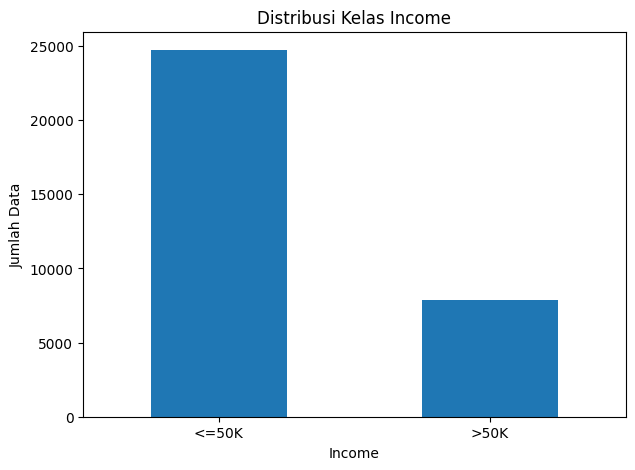

In [ ]:
print("==========D1==============")
import matplotlib.pyplot as plt

# Distribusi target
class_counts = df["income"].value_counts()

print("Distribusi kelas:")
print(class_counts)

# Persentase
class_percent = df["income"].value_counts(normalize=True) * 100

print("\nPersentase kelas:")
print(class_percent.round(2))

# Rasio imbalance
majority_count = class_counts.max()
minority_count = class_counts.min()

imbalance_ratio = majority_count / minority_count

print("\nRasio ketidakseimbangan:")
print(f"{imbalance_ratio:.2f}:1")

# Bar chart
plt.figure(figsize=(7, 5))
class_counts.plot(kind="bar")

plt.title("Distribusi Kelas Income")
plt.xlabel("Income")
plt.ylabel("Jumlah Data")
plt.xticks(rotation=0)
plt.show()

### D1. Distribusi Kelas dan Rasio Ketidakseimbangan

Berdasarkan hasil `value_counts()`, distribusi target `income` menunjukkan bahwa kelas `<=50K` merupakan kelas mayoritas, sedangkan `>50K` merupakan kelas minoritas. Jumlah data untuk kelas `<=50K` adalah 24.720 dan kelas `>50K` adalah 7.841.

Rasio ketidakseimbangan dihitung dengan membagi jumlah kelas mayoritas dengan jumlah kelas minoritas:

**Rasio imbalance = 24.720 / 7.841 ≈ 3,15 : 1**

Artinya, terdapat sekitar 3,15 data dengan income `<=50K` untuk setiap 1 data dengan income `>50K`.

Berdasarkan rasio tersebut, dataset Adult dapat dikategorikan sebagai **moderately imbalanced**, karena rasio ketidakseimbangannya berada sedikit di atas 3:1.


In [ ]:
print("==========D2=============")

# ============================================================
# D2 — TRAIN-TEST SPLIT
# ============================================================

import pandas as pd
from sklearn.model_selection import train_test_split

# ------------------------------------------------------------
# 1. Separate features and target
# ------------------------------------------------------------

X = df.drop(columns=["income"]).copy()
y = df["income"].copy()

# Clean target values
y = (
    y.astype(str)
     .str.strip()
     .str.replace(".", "", regex=False)
)

# ------------------------------------------------------------
# 2. Train-test split
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# ------------------------------------------------------------
# 3. Display results
# ------------------------------------------------------------

print("=" * 60)
print("D2 — TRAIN-TEST SPLIT")
print("=" * 60)

print("\nUkuran dataset awal:")
print(df.shape)

print("\nUkuran X_train:")
print(X_train.shape)

print("\nUkuran X_test:")
print(X_test.shape)

print("\nUkuran y_train:")
print(y_train.shape)

print("\nUkuran y_test:")
print(y_test.shape)

print("\nDistribusi kelas y_train:")
print(y_train.value_counts())

print("\nPersentase kelas y_train:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nDistribusi kelas y_test:")
print(y_test.value_counts())

print("\nPersentase kelas y_test:")
print((y_test.value_counts(normalize=True) * 100).round(2))

==========D2=============
D2 — TRAIN-TEST SPLIT

Ukuran dataset awal:
(32561, 15)

Ukuran X_train:
(26048, 14)

Ukuran X_test:
(6513, 14)

Ukuran y_train:
(26048,)

Ukuran y_test:
(6513,)

Distribusi kelas y_train:
income
<=50K    19775
>50K      6273
Name: count, dtype: int64

Persentase kelas y_train:
income
<=50K    75.92
>50K     24.08
Name: proportion, dtype: float64

Distribusi kelas y_test:
income
<=50K    4945
>50K     1568
Name: count, dtype: int64

Persentase kelas y_test:
income
<=50K    75.93
>50K     24.07
Name: proportion, dtype: float64


Penjelasan D2 — Pembagian Data Sebelum Balancing

Pada tahap D2, dataset terlebih dahulu dibagi menjadi data latih (training data) dan data uji (testing data) sebelum dilakukan proses balancing. Pembagian dilakukan menggunakan train_test_split() dengan proporsi 80% data training dan 20% data testing.

Parameter stratify=y digunakan agar proporsi kelas target income pada data training dan data testing tetap seimbang dengan proporsi pada dataset awal. Dengan demikian, kelas <=50K dan >50K tetap memiliki persentase yang relatif sama pada kedua bagian data.

Balancing harus dilakukan setelah train-test split dan hanya pada data training. Hal ini karena data testing harus tetap merepresentasikan kondisi data asli yang belum pernah dilihat oleh model. Jika balancing dilakukan sebelum pembagian data, informasi dari proses balancing dapat masuk ke data testing sehingga menyebabkan data leakage dan hasil evaluasi model menjadi kurang dapat dipercaya.

In [ ]:
# ============================================================
# D3 — DATA BALANCING
# ============================================================

import pandas as pd
from sklearn.preprocessing import OneHotEncoder
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler


# ============================================================
# 1. ORDINAL ENCODING FOR EDUCATION
# ============================================================

education_order = [
    "Preschool",
    "1st-4th",
    "5th-6th",
    "7th-8th",
    "9th",
    "10th",
    "11th",
    "12th",
    "HS-grad",
    "Some-college",
    "Assoc-voc",
    "Assoc-acdm",
    "Bachelors",
    "Masters",
    "Prof-school",
    "Doctorate"
]

education_mapping = {
    category: number
    for number, category in enumerate(education_order)
}

X_train["education"] = X_train["education"].map(education_mapping)
X_test["education"] = X_test["education"].map(education_mapping)


# ============================================================
# 2. ONE-HOT ENCODING FOR NOMINAL CATEGORICAL FEATURES
# ============================================================

nominal_columns = [
    "workclass",
    "marital-status",
    "occupation",
    "relationship",
    "race",
    "sex",
    "native-country"
]

encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

# Fit ONLY on training data
X_train_encoded_array = encoder.fit_transform(
    X_train[nominal_columns].fillna("Missing")
)

# Transform test data using the SAME encoder
X_test_encoded_array = encoder.transform(
    X_test[nominal_columns].fillna("Missing")
)

encoded_columns = encoder.get_feature_names_out(
    nominal_columns
)

X_train_encoded = pd.DataFrame(
    X_train_encoded_array,
    columns=encoded_columns,
    index=X_train.index
)

X_test_encoded = pd.DataFrame(
    X_test_encoded_array,
    columns=encoded_columns,
    index=X_test.index
)


# ============================================================
# 3. REMOVE ORIGINAL NOMINAL COLUMNS
# ============================================================

X_train = X_train.drop(columns=nominal_columns)
X_test = X_test.drop(columns=nominal_columns)


# ============================================================
# 4. COMBINE NUMERICAL + ENCODED FEATURES
# ============================================================

X_train = pd.concat(
    [X_train, X_train_encoded],
    axis=1
)

X_test = pd.concat(
    [X_test, X_test_encoded],
    axis=1
)


# ============================================================
# 5. MAKE SURE ALL FEATURES ARE NUMERIC
# ============================================================

X_train = X_train.apply(pd.to_numeric, errors="coerce")
X_test = X_test.apply(pd.to_numeric, errors="coerce")


# ============================================================
# 6. CONVERT TARGET TO 0/1
# ============================================================

y_train = y_train.map({
    "<=50K": 0,
    ">50K": 1
})

y_test = y_test.map({
    "<=50K": 0,
    ">50K": 1
})


# ============================================================
# 7. CHECK BEFORE BALANCING
# ============================================================

print("=" * 60)
print("D3 — BEFORE BALANCING")
print("=" * 60)

print("\nX_train shape:")
print(X_train.shape)

print("\nX_test shape:")
print(X_test.shape)

print("\ny_train:")
print(y_train.value_counts())

print("\ny_test:")
print(y_test.value_counts())

print("\nObject columns:")
print(X_train.select_dtypes(include=["object"]).columns.tolist())


# ============================================================
# 8. RANDOM UNDERSAMPLING
# ============================================================

under_sampler = RandomUnderSampler(
    random_state=42
)

X_train_under, y_train_under = under_sampler.fit_resample(
    X_train,
    y_train
)


# ============================================================
# 9. RANDOM OVERSAMPLING
# ============================================================

over_sampler = RandomOverSampler(
    random_state=42
)

X_train_over, y_train_over = over_sampler.fit_resample(
    X_train,
    y_train
)


# ============================================================
# 10. DISPLAY BALANCING RESULTS
# ============================================================

print("\n" + "=" * 60)
print("AFTER RANDOM UNDERSAMPLING")
print("=" * 60)

print(y_train_under.value_counts())

print("\nUkuran:")
print(X_train_under.shape)


print("\n" + "=" * 60)
print("AFTER RANDOM OVERSAMPLING")
print("=" * 60)

print(y_train_over.value_counts())

print("\nUkuran:")
print(X_train_over.shape)

D3 — BEFORE BALANCING

X_train shape:
(26048, 93)

X_test shape:
(6513, 93)

y_train:
income
0    19775
1     6273
Name: count, dtype: int64

y_test:
income
0    4945
1    1568
Name: count, dtype: int64

Object columns:
[]

AFTER RANDOM UNDERSAMPLING
income
0    6273
1    6273
Name: count, dtype: int64

Ukuran:
(12546, 93)

AFTER RANDOM OVERSAMPLING
income
1    19775
0    19775
Name: count, dtype: int64

Ukuran:
(39550, 93)


Pada D3, kami menerapkan Random Undersampling dan Random Oversampling hanya pada data training. Undersampling mengurangi kelas mayoritas, sedangkan oversampling menambah kelas minoritas hingga distribusi kelas menjadi seimbang. Data testing tidak diubah agar tetap merepresentasikan distribusi data asli.

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c

D4 — PERBANDINGAN HASIL MODEL
              Method  Accuracy  Precision  Recall  F1-Score
     Tanpa Balancing    0.8420     0.7207  0.5612    0.6311
Random Undersampling    0.7898     0.5416  0.8253    0.6540
 Random Oversampling    0.7867     0.5370  0.8284    0.6516

Tanpa Balancing
Confusion Matrix:
[[4604  341]
 [ 688  880]]


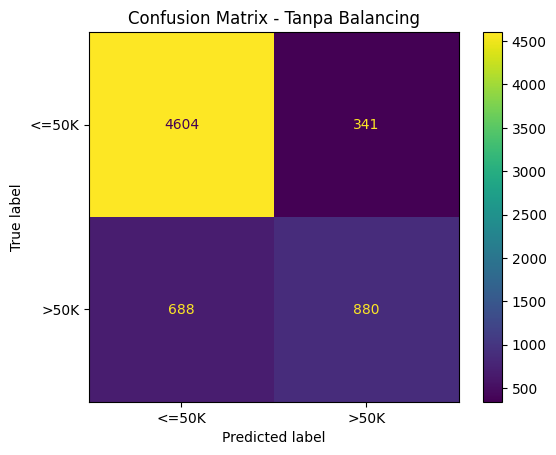


Random Undersampling
Confusion Matrix:
[[3850 1095]
 [ 274 1294]]


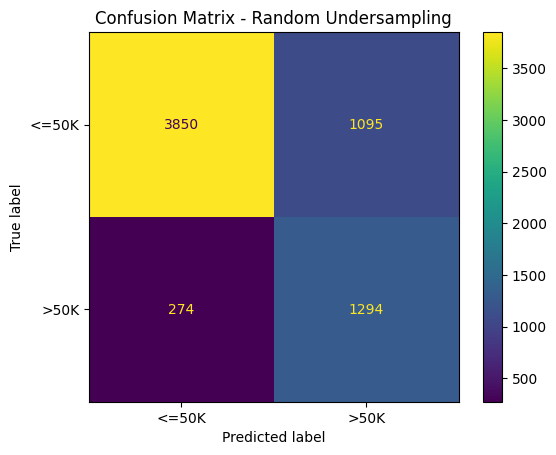


Random Oversampling
Confusion Matrix:
[[3825 1120]
 [ 269 1299]]


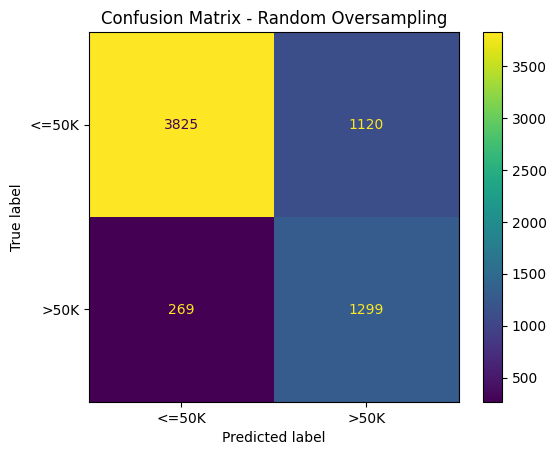

In [ ]:
# ============================================================
# D4 — MODEL KLASIFIKASI
# ============================================================

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. MODEL A — TANPA BALANCING
# ============================================================

model_original = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model_original.fit(
    X_train,
    y_train
)

y_pred_original = model_original.predict(
    X_test
)


# ============================================================
# 2. MODEL B — RANDOM UNDERSAMPLING
# ============================================================

model_under = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model_under.fit(
    X_train_under,
    y_train_under
)

y_pred_under = model_under.predict(
    X_test
)


# ============================================================
# 3. MODEL C — RANDOM OVERSAMPLING
# ============================================================

model_over = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model_over.fit(
    X_train_over,
    y_train_over
)

y_pred_over = model_over.predict(
    X_test
)


# ============================================================
# 4. CALCULATE METRICS
# ============================================================

results = pd.DataFrame({

    "Method": [
        "Tanpa Balancing",
        "Random Undersampling",
        "Random Oversampling"
    ],

    "Accuracy": [
        accuracy_score(y_test, y_pred_original),
        accuracy_score(y_test, y_pred_under),
        accuracy_score(y_test, y_pred_over)
    ],

    "Precision": [
        precision_score(
            y_test,
            y_pred_original,
            zero_division=0
        ),

        precision_score(
            y_test,
            y_pred_under,
            zero_division=0
        ),

        precision_score(
            y_test,
            y_pred_over,
            zero_division=0
        )
    ],

    "Recall": [
        recall_score(
            y_test,
            y_pred_original,
            zero_division=0
        ),

        recall_score(
            y_test,
            y_pred_under,
            zero_division=0
        ),

        recall_score(
            y_test,
            y_pred_over,
            zero_division=0
        )
    ],

    "F1-Score": [
        f1_score(
            y_test,
            y_pred_original,
            zero_division=0
        ),

        f1_score(
            y_test,
            y_pred_under,
            zero_division=0
        ),

        f1_score(
            y_test,
            y_pred_over,
            zero_division=0
        )
    ]
})


# ============================================================
# 5. DISPLAY RESULTS
# ============================================================

print("=" * 70)
print("D4 — PERBANDINGAN HASIL MODEL")
print("=" * 70)

print(
    results.round(4).to_string(index=False)
)


# ============================================================
# 6. CONFUSION MATRIX — THREE MODELS
# ============================================================

predictions = {
    "Tanpa Balancing": y_pred_original,
    "Random Undersampling": y_pred_under,
    "Random Oversampling": y_pred_over
}

for method, prediction in predictions.items():

    cm = confusion_matrix(
        y_test,
        prediction
    )

    print("\n" + "=" * 60)
    print(method)
    print("=" * 60)

    print("Confusion Matrix:")
    print(cm)

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["<=50K", ">50K"]
    ).plot()

    plt.title(
        f"Confusion Matrix - {method}"
    )

    plt.show()

### D5. Mengapa accuracy saja bisa menyesatkan pada dataset yang imbalanced?

Accuracy saja dapat menyesatkan pada dataset yang imbalanced karena accuracy hanya menunjukkan persentase seluruh prediksi yang benar, tanpa memperhatikan distribusi masing-masing kelas. Pada dataset Adult, kelas `<=50K` merupakan kelas mayoritas, sedangkan `>50K` merupakan kelas minoritas. Oleh karena itu, sebuah model dapat memperoleh accuracy yang cukup tinggi karena sebagian besar data berasal dari kelas mayoritas, meskipun model masih kurang baik dalam mengenali kelas minoritas.

Hal ini dapat dilihat melalui confusion matrix dari D4. Confusion matrix menunjukkan jumlah **True Positive (TP), True Negative (TN), False Positive (FP), dan False Negative (FN)**. Jika model menghasilkan banyak **False Negative (FN)**, berarti data yang sebenarnya termasuk kelas `>50K` diprediksi sebagai `<=50K`. Kesalahan tersebut dapat menjadi penting meskipun nilai accuracy model tetap terlihat tinggi.

Oleh karena itu, accuracy sebaiknya tidak digunakan sebagai satu-satunya metrik pada dataset yang imbalanced. Precision, recall, F1-score, dan confusion matrix dapat memberikan informasi yang lebih lengkap mengenai kemampuan model dalam mengenali kelas minoritas. Dengan membandingkan hasil model tanpa balancing, random undersampling, dan random oversampling, dapat dilihat bagaimana proses balancing memengaruhi performa model pada masing-masing kelas.


Analisis & **Refleksi**



1. pipeline pre-processing
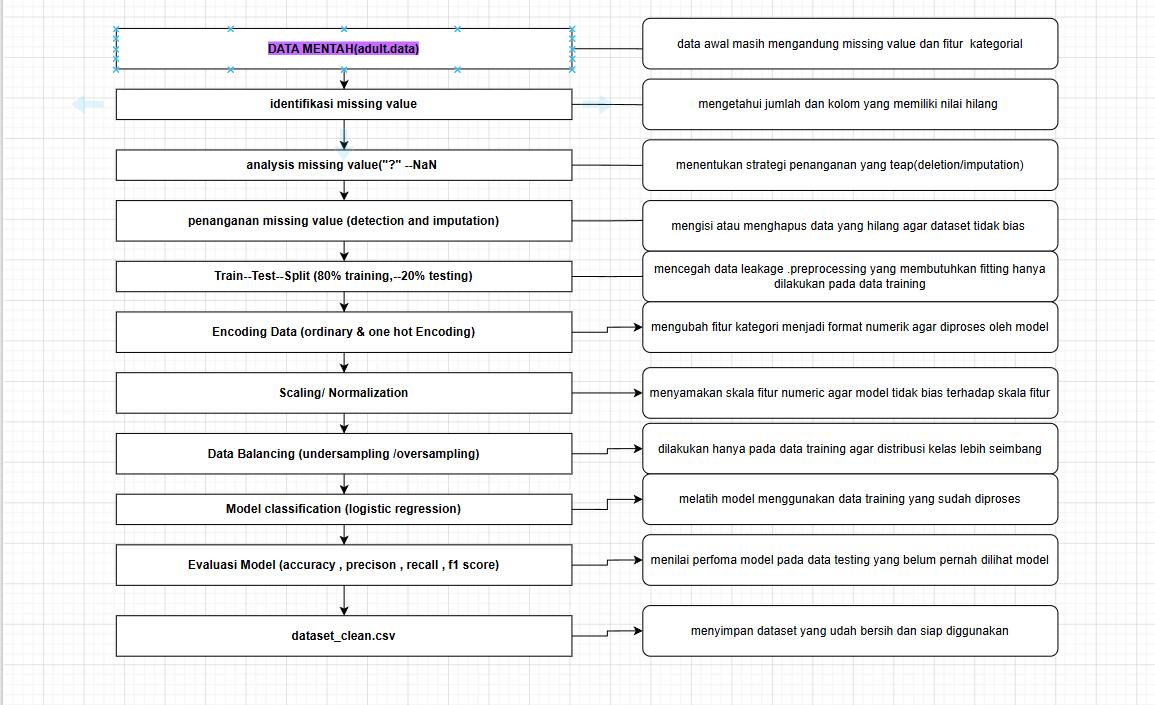
2. Tahap yang paling berdampak pada kualitas data
Menurut hasil yang didapat, tahap yang paling berdampak adalah data balancing yang dimana Pada dataset Adult, jumlah datanya tidak seimbang. Kelas <=50K memiliki 24.720 data, sedangkan kelas >50K hanya 7.841 data. Karena jumlahnya berbeda cukup jauh maka kami melakukan  balancing supaya kedua kelas lebih seimbang. Pada data training, undersampling membuat jumlah data menjadi 6.272 : 6.272, sedangkan oversampling menjadi 19.776 : 19.776. Dengan begitu, model dapat belajar dari kedua kelas dengan lebih seimbang lalu Hasilnya kemudian dapat dibandingkan menggunakan accuracy, precision, recall, dan F1-score.
3. Jika dataset jauh lebih besar
Kalau dataset yang digunakan jauh lebih besar, misalnya sampai jutaan data, proses pengolahan data akan membutuhkan waktu dan memori yang lebih banyak maka Oversampling juga bisa membuat ukuran dataset semakin besar karena data dari kelas minoritas akan digandakan.Salah satu cara yang kami gunakan  untuk mengatasinya adalah menggunakan class weighting. Dengan cara ini, kelas yang jumlahnya sedikit bisa diberi bobot lebih besar tanpa harus menggandakan datanya.kami juga menggunakan caraPreprocessing yang diaman cara ini juga bisa memengaruhi hasil model. Contohnya, pada undersampling sebagian data dari kelas mayoritas dihapus sehingga ada informasi yang mungkin hilang. Sedangkan oversampling mempertahankan data mayoritas, tetapi data dari kelas minoritas akan diulang.Oleh Karena itu, preprocessing harus dilakukan dengan hati-hati dan hasil model sebaiknya tidak hanya dilihat dari accuracy, tetapi juga dari precision, recall, dan F1-score.
4. Kesimpulan
Dari proses yang dilakukan, setiap tahap preprocessing memiliki fungsi masing-masing. Missing value ditangani agar data lebih bersih, encoding digunakan agar data kategori bisa diproses oleh model, scaling digunakan untuk menyamakan skala data, dan balancing digunakan untuk mengatasi jumlah kelas yang tidak seimbang.
Pada dataset Adult, balancing cukup penting karena jumlah kelas <=50K dan >50K berbeda cukup jauh. Setelah itu, hasil model dibandingkan menggunakan accuracy, precision, recall, dan F1-score untuk melihat performa model dengan lebih lengkap.

